## Topic Analysis of Research Document
Question 3

In [1]:
import re, string, zipfile, unicodedata
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.probability import FreqDist
from nltk import pos_tag
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from wordcloud import WordCloud

# NLTK data for sentence splitting, stop words, lemmatising and POS tagging
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'averaged_perceptron_tagger_eng']:
    nltk.download(pkg, quiet=True)

### Question 3.1 = Dataframe of research articles

In [2]:
# Read each .txt straight out of the zip, no need to extract it first
rows = []
with zipfile.ZipFile('research_corpus.zip') as z:
    for name in sorted(n for n in z.namelist() if n.endswith('.txt')):
        rows.append({'article': name.split('/')[-1].replace('.txt', ''),
                     'content': z.read(name).decode('utf-8', errors='ignore')})

df = pd.DataFrame(rows)
# Rough word count of the raw text, so I can see later how much the cleaning removed
df['words'] = df['content'].str.split().str.len()
df

,article,content,words
0,research_1,The purposes of this article are to position m...,5602
1,research_2,"Now I see it, now I don’t:\r\nresearcher’s pos...",2416
2,research_3,DEVELOPMENTAL RESEARCH: STUDIES OF\r\nINSTRUCT...,3828
3,research_4,Abstract\r\nCronbach’s alpha is a statistic co...,5922
4,research_5,Denzin’s Paradigm Shift: Revisiting Triangulat...,4027


### Question 3.2 = Denoising the article content

##### Document level denoising

In [3]:
# The articles were copied out of PDFs and web pages, so there are lots of junk lines:
# page numbers, running headers, e-mail addresses, figure labels... This catches the ones I found.
NOISE_LINE = re.compile(
    r'^\d+$'                                    # page numbers
    r'|^\d+\s+[A-Z][A-Z\s]+$'                   # running header: 16 EDUCATIONAL RESEARCHER
    r'|^[A-Z]+\s+\d{4}\s+\d+$'                  # running header: OCTOBER 2004 15
    r'|•'                                  # running header: 1100 • RICHEY, KLEIN, NELSON
    r'|^Journal of .* \d+$'                     # running footer: Journal of Social Change 20
    r'|^\d+\s+Qualitative Research'             # running header: 220 Qualitative Research 15(2)
    r'|^[A-Z][a-z]+ \d{3}$'                     # running header: Berger 221
    r'|^(Keywords|Article|Abstract|Corresponding author:?|Full size image)$'
    r'|^(Fig\.|figure)\s*\d+'                   # figure labels
    r'|@'                                       # e-mail addresses
    r'|^[^.]{0,60}University[^.]{0,30}$',       # author affiliations
    re.I)

# Little words that usually stay lowercase even inside a title
SMALL_WORDS = {'a', 'an', 'and', 'as', 'at', 'by', 'for', 'in', 'of', 'on', 'or', 'the', 'to', 'vs', 'with'}

# A line counts as a heading if it's short, doesn't end like a sentence,
# and most of its words start with a capital letter
def is_heading(line):
    words = [w for w in re.findall(r"[A-Za-z][\w'-]*", line) if w.lower() not in SMALL_WORDS]
    return (len(line) < 80 and len(words) <= 10 and not re.search(r'[.,;?!)]$', line)
            and bool(words) and sum(w[0].isupper() for w in words) / len(words) >= 0.75)

# Cleans one whole article: first fix the raw text, then go through it line by line,
# and finally join everything back into normal running text
def denoise_document(text):
    text = unicodedata.normalize('NFKC', text)                                    # unicode normalisation
    text = text.replace('﻿', '').replace('\r', '')                           # byte-order marks, CRLF
    text = re.sub(r'Similar content being viewed by others.*?(?=\nIntroduction)', '', text, flags=re.S)  # web "related articles" block
    text = re.sub(r'Educational Researcher, Vol\. \d+, No\. \d+, pp\. \S+', ' ', text)                 # journal footer inside text
    text = re.sub(r'\nKeywords?:?\s*\n?.*?(?=\n[A-Z][a-z]+\s*\n|\nThe )', '\n', text, flags=re.S)   # keyword lists
    start = text[:200]                                                            # one file had the article pasted twice, so cut at the repeat
    if text.find(start, 200) > 0:
        text = text[:text.find(start, 200)]
    text = re.sub(r'[-]', ' ', text)                                  # private-use bullet symbols
    text = text.translate(str.maketrans({'“': '"', '”': '"', '‘': "'", '’': "'",
                                         '–': '-', '—': '-', '…': '...'}))

    # Now check every line and skip anything that clearly is not article text
    lines = [l.strip() for l in text.split('\n') if l.strip()]
    counts, seen, kept = Counter(lines), set(), []
    for l in lines:
        if NOISE_LINE.search(l):           continue    # headers, footers, page numbers, web leftovers
        if counts[l] >= 3 and len(l) < 60: continue    # other repeated running headers
        if l in seen and len(l) > 30:      continue    # duplicated blocks of text
        if is_heading(l):                  continue    # titles, section headings, author names
        seen.add(l); kept.append(l)

    text = ' '.join(kept)                                         # re-join lines broken by the PDF layout
    text = re.sub(r'(\w)- (\w)', r'\1\2', text)                   # words hyphenated across lines
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)            # URLs
    text = re.sub(r'\([^()]*\d{4}[^()]*\)', ' ', text)            # in-text citations (Author, 2004)
    text = re.sub(r'\(pp?\.\s*\d+[^)]*\)', ' ', text)             # page references (p. 12)
    text = re.sub(r'\b\d+(\.\d+)+\s+(?=[A-Z])', ' ', text)        # section numbers 41.2.1
    text = re.sub(r'(?<=[a-z])\.\d{1,2}(?=\s)', '.', text)        # footnote markers: research.5
    text = re.sub(r'[^\x00-\x7f]', ' ', text)                     # remaining non-ASCII symbols
    text = re.sub(r'\s+([.,;:])', r'\1', text)
    return re.sub(r'\s+', ' ', text).strip()

# Clean all five articles and have a look
df['clean_content'] = df['content'].apply(denoise_document)
df[['article', 'clean_content']]

,article,clean_content
0,research_1,The purposes of this article are to position m...
1,research_2,"Now I see it, now I don't: researcher's positi..."
2,research_3,The field of instructional technology has trad...
3,research_4,Cronbach's alpha is a statistic commonly quote...
4,research_5,"One approach to promote social change, mitigat..."


### Token-level normalisation

In [4]:
# NLTK's stop words plus some academic filler words that kept showing up at the top of the counts
stop_words = set(stopwords.words('english')) | {
    'also', 'may', 'one', 'two', 'would', 'could', 'well', 'use', 'used', 'using', 'et', 'al',
    'often', 'however', 'e', 'g', 'eg', 'ie', 'p', 'pp', 'within', 'among', 'example', 'way', 'much'}
lemmatizer = WordNetLemmatizer()

# Converts the POS tag into what WordNet expects, so 'studies' -> 'study' and 'found' -> 'find' work properly
def wordnet_pos(tag):
    return {'J': wordnet.ADJ, 'V': wordnet.VERB, 'R': wordnet.ADV}.get(tag[0], wordnet.NOUN)

# Turns a piece of text into a list of clean, lemmatised words
def preprocess(text):
    text = text.lower()
    text = re.sub(r'\d+', ' ', text)                                                           # numbers
    text = text.translate(str.maketrans(string.punctuation, ' ' * len(string.punctuation)))    # punctuation
    tokens = [w for w in word_tokenize(text) if w.isalpha() and len(w) > 2]                    # tokenise
    tokens = [lemmatizer.lemmatize(w, wordnet_pos(t)) for w, t in pos_tag(tokens)]             # POS-aware lemmatisation
    return [w for w in tokens if w not in stop_words and len(w) > 2]                           # stop words

# Filter for summary sentences: not too short, not too long, and ending properly
# (keeps out bits of tables and lines that got cut off)
def valid_sentence(s):
    return 8 <= len(s.split()) <= 60 and bool(re.search(r'[.?!]$', s)) and not re.search(r'(i\.e|e\.g)\.$', s)

# Sentences come from the cleaned text (punctuation still in), tokens are the fully processed words
df['sentences'] = df['clean_content'].apply(sent_tokenize)
df['tokens'] = df['clean_content'].apply(preprocess)
df['clean_text'] = df['tokens'].apply(' '.join)

# How much each step shrank the articles
summary = pd.DataFrame({'raw words': df['words'],
                        'after denoising': df['clean_content'].str.split().str.len(),
                        'final tokens': df['tokens'].str.len(),
                        'sentences': df['sentences'].str.len()})
summary.index = df['article']
summary

,raw words,after denoising,final tokens,sentences
article,,,,
research_1,5602,2574,1416,77
research_2,2416,2209,1115,64
research_3,3828,3551,1939,160
research_4,5922,5619,2960,187
research_5,4027,3547,1890,159


### Question 3.3 = Summary of the first article (frequency based extractive summarisation)

In [5]:
# Article 1 only, keeping just the usable sentences
article1 = df.loc[0]
sentences1 = [s for s in article1['sentences'] if valid_sentence(s)]

# Word weight = how often the word appears, scaled so the most common word is 1
freq = FreqDist(article1['tokens'])
max_freq = max(freq.values())
word_weight = {w: f / max_freq for w, f in freq.items()}

# Score each sentence by the average weight of its words. Averaging instead of summing
# stops long sentences from winning just because they're long
scores1 = []
for s in sentences1:
    words = preprocess(s)
    scores1.append(sum(word_weight.get(w, 0) for w in words) / len(words) if words else 0)

# Take the 5 best sentences, but put them back in their original order so the summary reads naturally
top_idx = sorted(np.argsort(scores1)[-5:])
summary1 = ' '.join(sentences1[i] for i in top_idx)

# Print the summary and how short it is compared to the full article
print(f"Original: {len(article1['clean_content'].split())} words | Summary: {len(summary1.split())} words "
      f"({len(summary1.split()) / len(article1['clean_content'].split()):.1%} of the article)\n")
for i in top_idx:
    print('-', sentences1[i], '\n')

Original: 2574 words | Summary: 106 words (4.1% of the article)

- Our purpose in writing this article is to present mixed methods research as the third research paradigm in educational research. 

- We hope the field will move beyond quantitative versus qualitative research arguments because, as recognized by mixed methods research, both quantitative and qualitative research are important and useful. 

- Mixed methods research as the third research paradigm can also help bridge the schism between quantitative and qualitative research. 

- For example, qualitative researchers should be free to use quantitative methods, and quantitative researchers should be free to use qualitative methods. 

- We contend that epistemological and paradigmatic ecumenicalism is within reach in the research paradigm of mixed methods research. 



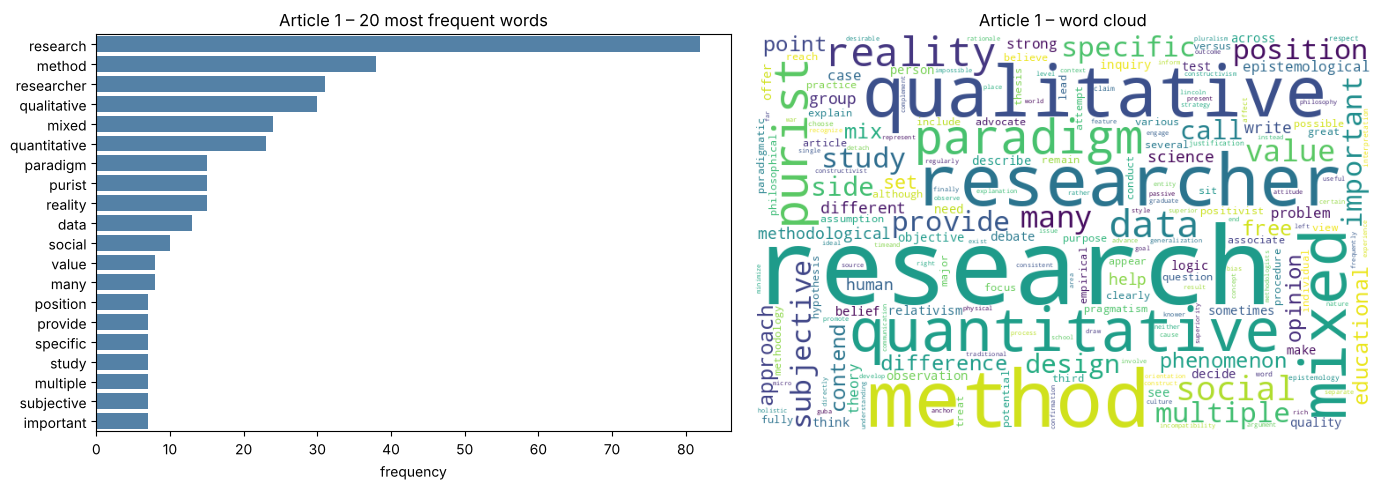

In [6]:
# Bar chart of the top words next to a word cloud of the same counts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top_words = pd.Series(dict(freq.most_common(20)))
sns.barplot(x=top_words.values, y=top_words.index, ax=axes[0], color='steelblue')
axes[0].set_title('Article 1 – 20 most frequent words'); axes[0].set_xlabel('frequency'); axes[0].set_ylabel('')

wc = WordCloud(width=700, height=450, background_color='white', colormap='viridis').generate_from_frequencies(freq)
axes[1].imshow(wc); axes[1].axis('off'); axes[1].set_title('Article 1 – word cloud')
plt.tight_layout(); plt.show()

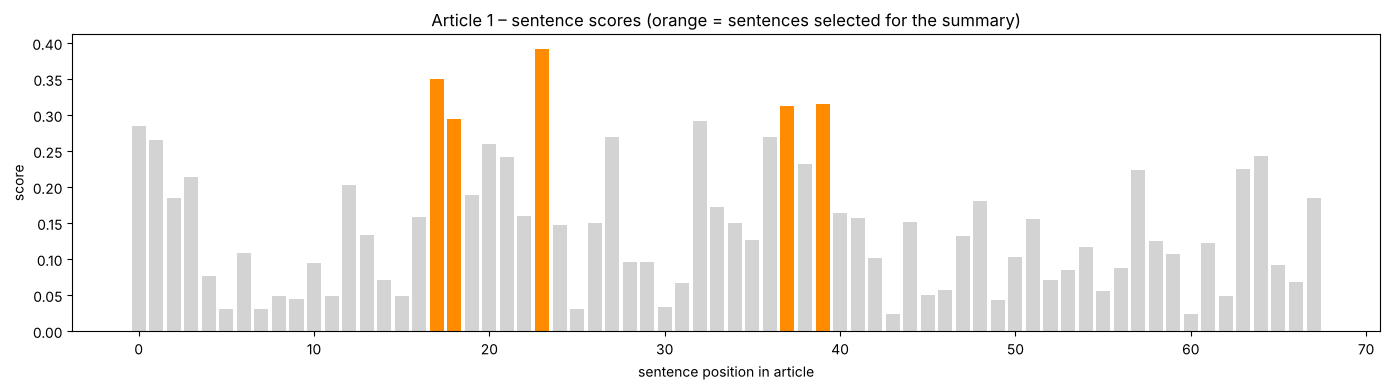

In [7]:
# Score of every sentence in article 1 - the orange bars are the 5 picked for the summary
colors = ['darkorange' if i in top_idx else 'lightgrey' for i in range(len(scores1))]
plt.figure(figsize=(14, 4))
plt.bar(range(len(scores1)), scores1, color=colors)
plt.title('Article 1 – sentence scores (orange = sentences selected for the summary)')
plt.xlabel('sentence position in article'); plt.ylabel('score')
plt.tight_layout(); plt.show()

**Comment:** The 5-sentence summary (about 4% of the article) shows that article 1 presents mixed methods research as a third research paradigm combining quantitative and qualitative research.

### Question 3.4 = Aggregate summary of the remaining articles (TextRank)

In [8]:
# Articles 2-5 go into one pool of sentences, remembering which article each sentence came from
rest = df.iloc[1:]
pool = [(row['article'], s) for _, row in rest.iterrows()
        for s in row['sentences'] if valid_sentence(s)]
pool_df = pd.DataFrame(pool, columns=['article', 'sentence'])
pool_df['processed'] = pool_df['sentence'].apply(lambda s: ' '.join(preprocess(s)))

# TextRank step 1: turn sentences into TF-IDF vectors and measure how similar each pair is
tfidf = TfidfVectorizer()
sent_vectors = tfidf.fit_transform(pool_df['processed'])
sim_matrix = cosine_similarity(sent_vectors)
np.fill_diagonal(sim_matrix, 0)     # a sentence shouldn't vote for itself

# Step 2: sentences are nodes, similarity is the edge weight, then run PageRank on it.
# Sentences that are similar to lots of other sentences get the highest scores
graph = nx.from_numpy_array(sim_matrix)
pool_df['textrank'] = pd.Series(nx.pagerank(graph, weight='weight'))


In [9]:
# Taking the top 2 per article makes sure every article is in the summary, not just the longest one
top_sent = pool_df.sort_values('textrank', ascending=False).groupby('article').head(2).sort_index()   # 2 best sentences per article
for _, r in top_sent.iterrows():
    print(f"[{r['article']}] {r['sentence']}\n")

[research_2] The main purpose of this article is to argue and illustrate that reflexivity in qualitative research is affected by whether the researcher is part of the researched and shares the participants' experience.

[research_2] Reflexivity is crucial throughout all phases of the research process, including the formulation of a research question, collection and analysis of data, and drawing conclusions.

[research_3] Early research methods texts addressed development as the "research and development" process.

[research_3] While instructional development typically builds on previous research, developmental research attempts to produce the models and principles that guide the design, development, and evaluation processes.

[research_4] It is common to see the reliability of instruments used in published science education studies framed in terms of a statistic known as Cronbach's alpha.

[research_4] However, the literature also includes reports of the development of tests of student

In [10]:
# The aggregate summary as one paragraph, and how much shorter it is than articles 2-5
aggregate_summary = ' '.join(top_sent['sentence'])
total_words = rest['clean_content'].str.split().str.len().sum()
print(f"Articles 2-5: {total_words} words | Aggregate summary: {len(aggregate_summary.split())} words "
      f"({len(aggregate_summary.split()) / total_words:.1%})\n")
print(aggregate_summary)

Articles 2-5: 14926 words | Aggregate summary: 201 words (1.3%)

The main purpose of this article is to argue and illustrate that reflexivity in qualitative research is affected by whether the researcher is part of the researched and shares the participants' experience. Reflexivity is crucial throughout all phases of the research process, including the formulation of a research question, collection and analysis of data, and drawing conclusions. Early research methods texts addressed development as the "research and development" process. While instructional development typically builds on previous research, developmental research attempts to produce the models and principles that guide the design, development, and evaluation processes. It is common to see the reliability of instruments used in published science education studies framed in terms of a statistic known as Cronbach's alpha. However, the literature also includes reports of the development of tests of student knowledge and und

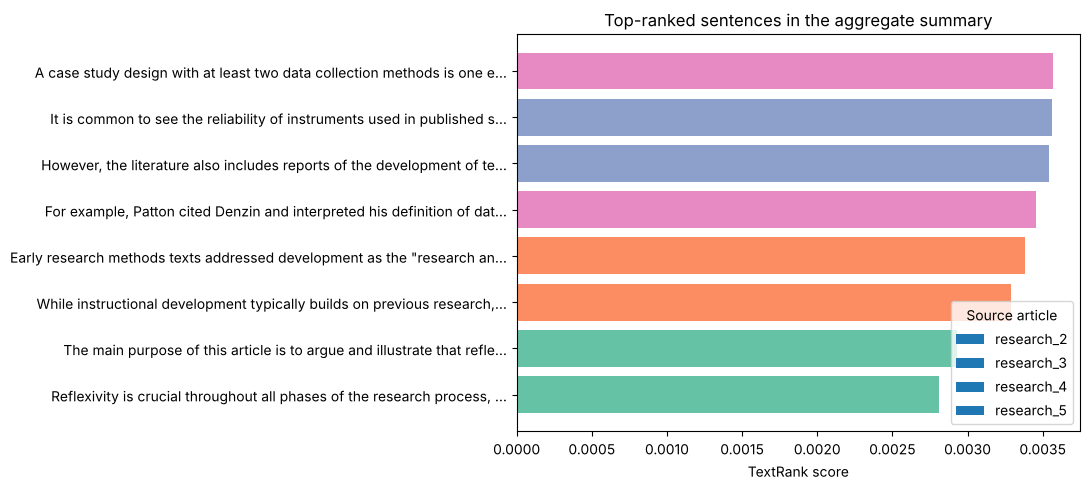

In [11]:
# Bar chart of the chosen sentences, coloured by the article they came from
palette = dict(zip(rest['article'], sns.color_palette('Set2', len(rest))))
plot_df = top_sent.sort_values('textrank')
plot_df['label'] = plot_df['sentence'].str[:70] + '...'

plt.figure(figsize=(11, 5))
plt.barh(plot_df['label'], plot_df['textrank'], color=plot_df['article'].map(palette))
# empty bars, just to get one legend entry per article
for a, c in palette.items():
    plt.barh([], [], color=c, label=a)
plt.legend(title='Source article'); plt.xlabel('TextRank score')
plt.title('Top-ranked sentences in the aggregate summary')
plt.tight_layout(); plt.show()

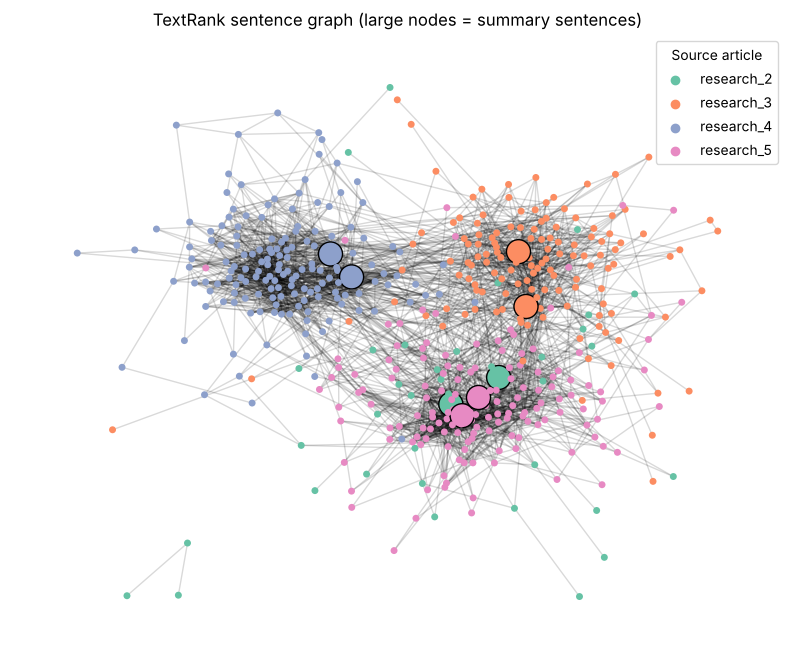

In [12]:
# The TextRank graph itself: each dot is a sentence, lines join similar sentences.
# Only the stronger links are drawn so it's readable; the big outlined dots are the summary sentences
strong = nx.Graph([(u, v) for u, v, w in graph.edges(data='weight') if w > 0.15])
pos = nx.spring_layout(strong, seed=42, k=0.15)
nodes = list(strong.nodes())
plt.figure(figsize=(10, 8))
nx.draw_networkx_edges(strong, pos, alpha=0.15)
nx.draw_networkx_nodes(strong, pos, nodelist=nodes,
                       node_color=[palette[pool_df.loc[n, 'article']] for n in nodes],
                       node_size=[300 if n in top_sent.index else 25 for n in nodes],
                       edgecolors=['black' if n in top_sent.index else 'none' for n in nodes])
for a, col in palette.items():
    plt.scatter([], [], color=col, label=a)
plt.legend(title='Source article'); plt.axis('off')
plt.title('TextRank sentence graph (large nodes = summary sentences)')
plt.show()

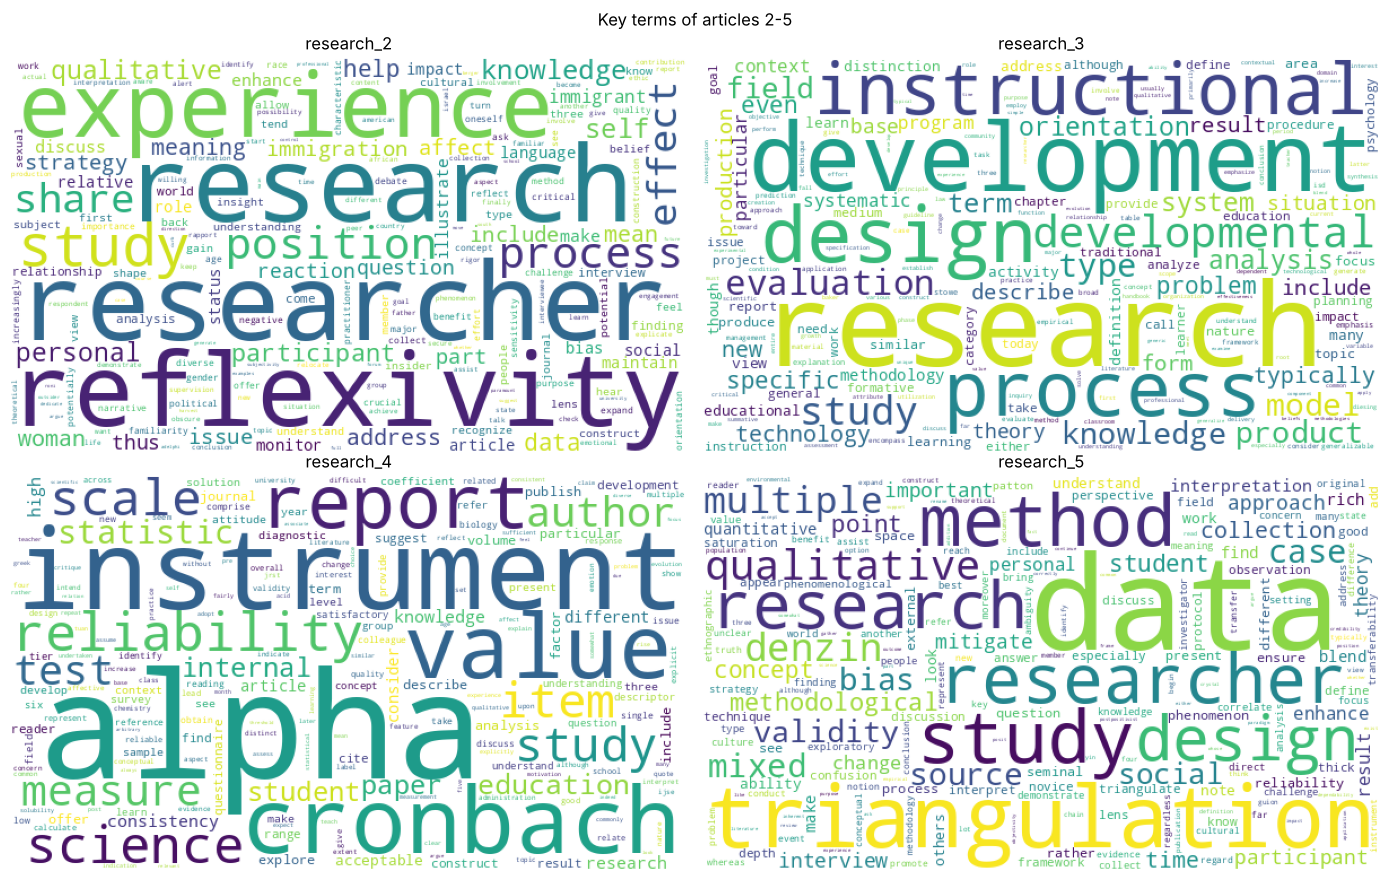

In [13]:
# One word cloud per article to show what each one is mostly about
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (_, row) in zip(axes.ravel(), rest.iterrows()):
    wc = WordCloud(width=600, height=350, background_color='white', colormap='viridis').generate_from_frequencies(Counter(row['tokens']))
    ax.imshow(wc); ax.axis('off'); ax.set_title(row['article'])
plt.suptitle('Key terms of articles 2-5'); plt.tight_layout(); plt.show()

**Comment:** TextRank reduces articles 2–5 to 8 sentences, about 1% of the text. The sentence graph forms one cluster per article, and the summary sentences sit at the centre of their clusters. The aggregate summary covers the main theme of each article: reflexivity in qualitative research (research_2), developmental research in instructional design (research_3), Cronbach's alpha as a reliability measure (research_4) and triangulation (research_5).